# 06 — Validation: Chebyshev fitting and evaluation

**What this notebook does:** tests TEMPUS's Chebyshev module (`tempus.chebycode`, the library behind `tempus chebyshev`) on two questions. *Fitting:* does a chebycode fit represent an integration as well as an established Chebyshev product? *Evaluation:* does reading coefficients back with chebycode match CALCEPH on identical coefficients?

**Why the Moon's orbit, not TCX − TCB:** the fitting benchmark is an INPOP run that provides both its raw integration output and the Chebyshev file INPOP built from it, so a chebycode fit can be judged against an official product made from exactly the same samples. Here those samples are the Moon's geocentric orbit and libration angles.

**Expected key results:** chebycode reproduces INPOP's own Chebyshev file to 2.5 µm, so both represent the raw Moon orbit at the same 0.47 mm max / 0.03 mm RMS. chebycode and CALCEPH evaluate identical coefficients to ≤ 1 ulp (~4×10⁻¹⁶ s), with 99.99 % of epochs bit-identical — the numbers quoted in the paper's Chebyshev section.

**Required data files:** `../data/cheby_benchmarks/I9_AA140525bpoutcar.dat` and `I9_AA140525b.tcheb` — an INPOP benchmark run that is not distributed, so §1–5 cannot be re-run without it; their outputs are kept in this notebook. §6 needs only the public `../data/ephem/inpop19a_TCB_m100_p100_tcg.dat` and `../data/time_ephem/inpop19a_TCB_m100_p100_asc_pos_TCG.asc`.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from calcephpy import CalcephBin, Constants, NaifId

from tempus import TimeScalar, jd_split
from tempus.chebycode import ChebyshevSeries
from tempus.ephem import CalcephEphem
from tempus.model import TimeGrid
from nb_utils import plot_compare_p, plot_compare_v, plot_compare_angle, plot_compare_angledot

PATH_POUTCAR = Path("../data/cheby_benchmarks/I9_AA140525bpoutcar.dat").resolve()
PATH_TCHEB   = Path("../data/cheby_benchmarks/I9_AA140525b.tcheb").resolve()


## 1 · The benchmark run

Two files from one INPOP integration. `…bpoutcar.dat` is its raw output: every 0.75 d for 28.7 yr from J2000, the barycentric states of the planets, the geocentric Moon and the Moon's libration angles, in AU and days. `…b.tcheb` is the Chebyshev file INPOP built from that output. Only the Moon is used below.


In [2]:
_F = np.longdouble

def load_poutcar(filepath):
    
    # Column meanings per the header:
    # Row type "Time*":  TDB, TT, empty, empty, empty, empty
    # Row type "PV_*":   X,   Y,  Z,    Vx,    Vy,    Vz
    # Row type "AngLib_Moo": Phi, Theta, Psi, Phi_dot, Theta_dot, Psi_dot

    # Units are AU and DAYS. Planet Coords are w.r.t. 0 (SSB). Moon Coord is w.r.t. 399 (EARTH_CENTER)

    # double check order of these labels with initial values at the end of mastrocst.dat
    ROW_LABELS = ['Time','PV_Mer','PV_Ven','PV_EMB','PV_Mar','PV_Jup','PV_Sat','PV_Ura','PV_Nep','PV_Plu','PV_Moo','PV_Sun','AngLib_Moo']
    BLOCK_SIZE = 13
    N_COLS = 6

    # First pass: count data lines to preallocate
    with open(filepath, 'r', encoding='utf-8') as f:
        lines = [l for l in f.readlines() if l.strip()]

    n_blocks = len(lines) // BLOCK_SIZE
    data = {label: np.empty((n_blocks, N_COLS), dtype=_F) for label in ROW_LABELS}

    for i, line in enumerate(lines):
        block_idx = i // BLOCK_SIZE
        row_idx   = i %  BLOCK_SIZE
        label     = ROW_LABELS[row_idx]
        values    = np.array(line.split()[:N_COLS], dtype=_F)
        data[label][block_idx] = values

    return data

In [3]:
data = load_poutcar(PATH_POUTCAR)

# The Time column counts TDB days from the run start, J2000.0 = JD 2451545.0 TDB. The §2 match
# with the .tcheb (≤ 0.5 mm at ~1 km/s) confirms that epoch alignment to < 1 µs.
JD_J2000 = 2451545
jd_tdb   = data["Time"][:, 0]      # TDB days since J2000, every 0.75 d
pv_moon  = data["PV_Moo"]          # geocentric Moon [AU, AU/day]
p_moon   = pv_moon[:, :3]
v_moon   = pv_moon[:, 3:]


## 2 · INPOP's Chebyshev file vs its raw integration

CALCEPH evaluates the `.tcheb` at the raw output epochs; the last 36 d of raw output lie beyond the file and are dropped. The difference is INPOP's own representation error — the reference level for the chebycode fit in §3.

Each figure plots, per component, CALCEPH minus the raw output: Moon position [AU], velocity [AU/day], then the libration angles φ, θ, ψ [rad, unwrapped] and their rates [rad/day]. The first angle figure also shows the values themselves.


In [4]:
peph = CalcephBin.open(str(PATH_TCHEB))
AU = peph.getconstant("AU")        # km

lastidx = -48                      # the last 48 samples (36 d) lie beyond the .tcheb

pv_calceph = []
orient_calceph = []
jd_int = []
jd_frac = []
for jd in jd_tdb[:lastidx]:
    jd0 = int(jd)
    dt  = np.float64(jd) - np.float64(jd0)
    jd0 += JD_J2000
    jd_int.append(jd0)
    jd_frac.append(dt)
    # Moon wrt Earth (301 wrt 399) and the lunar libration angles; CALCEPH returns float64
    PV = peph.compute_unit(jd0, dt, 301, 399, Constants.UNIT_AU + Constants.UNIT_DAY + Constants.USE_NAIFID)
    O  = peph.orient_unit(jd0, dt, NaifId.MOON, Constants.USE_NAIFID + Constants.UNIT_RAD + Constants.UNIT_DAY)
    pv_calceph.append(PV)
    orient_calceph.append(O)

peph.close()

jd_int = np.array(jd_int)
jd_frac = np.array(jd_frac)
jds = jd_int + jd_frac             # combined JD, for plot axes only
pv_calceph = np.array(pv_calceph)
orient_calceph = np.array(orient_calceph)
pv_rawout = data["PV_Moo"][:lastidx]
orient_rawout = data["AngLib_Moo"][:lastidx]


In [5]:
dp = (pv_calceph[:, :3] - pv_rawout[:, :3]).astype(np.float64) * AU * 1e6   # mm
print(f"Moon position, .tcheb - raw output: max {np.max(np.abs(dp)):.2f} mm, RMS {np.sqrt(np.mean(dp**2)):.2f} mm")


Moon position, .tcheb - raw output: max 0.47 mm, RMS 0.03 mm


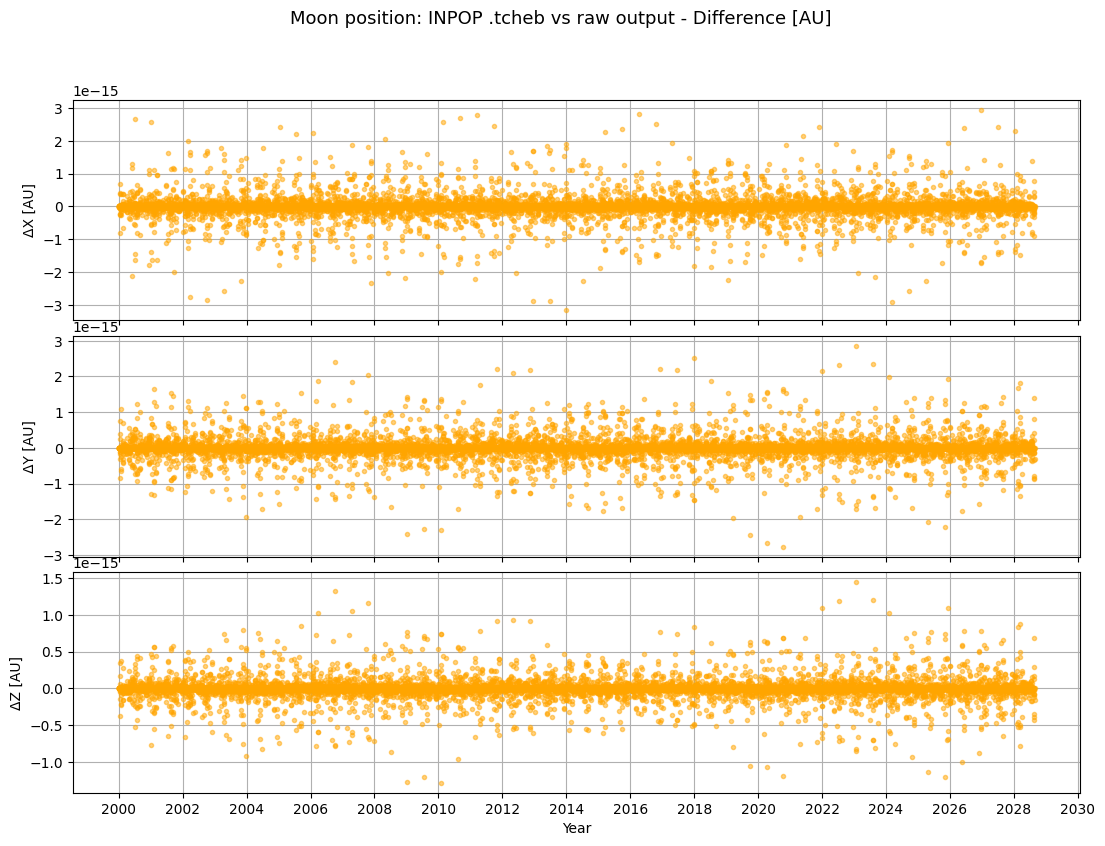

In [6]:
plot_compare_p(jds, pv_calceph, pv_rawout, label="Moon position: INPOP .tcheb vs raw output", show_overview=0)


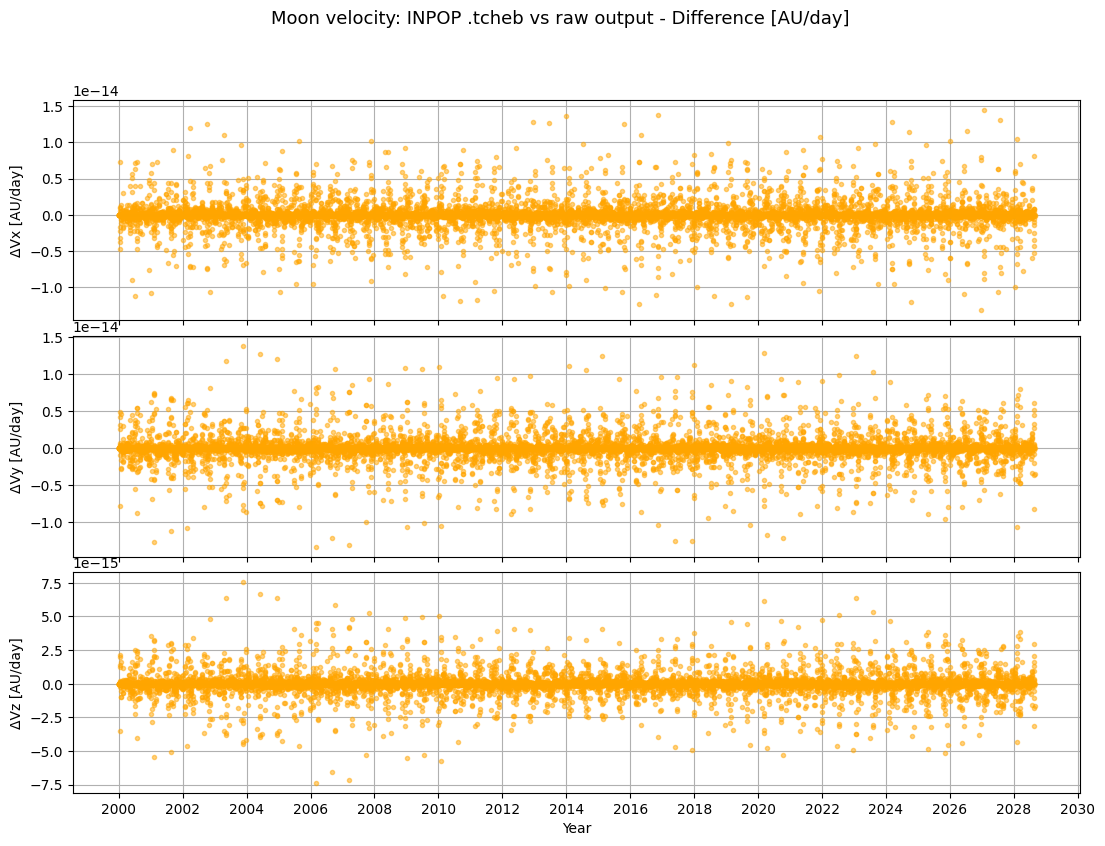

In [7]:
plot_compare_v(jds, pv_calceph, pv_rawout, label="Moon velocity: INPOP .tcheb vs raw output")

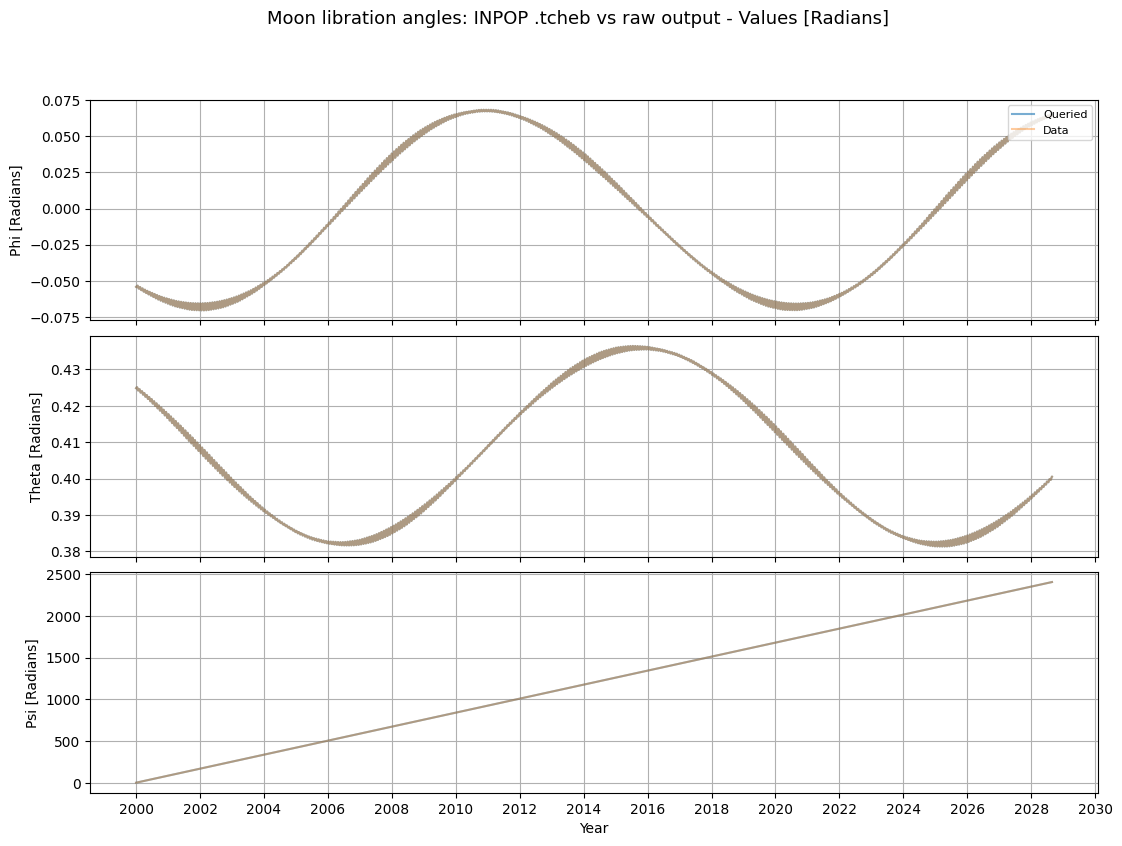

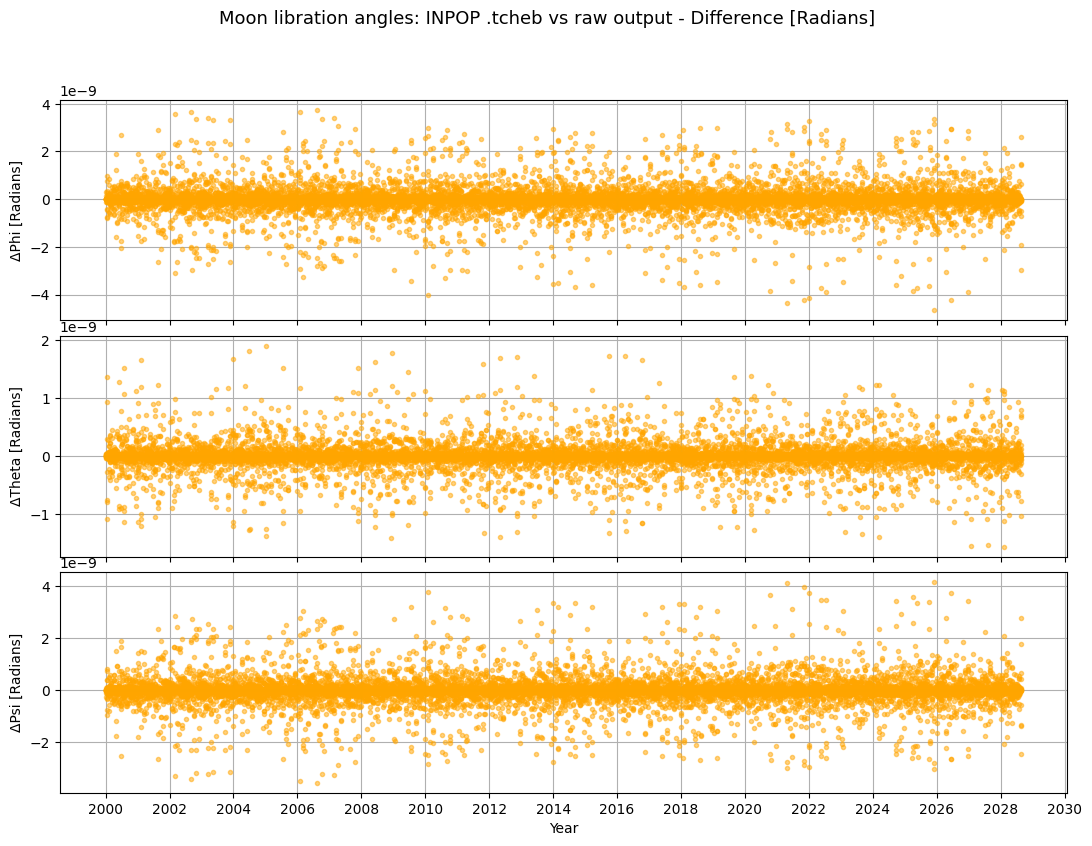

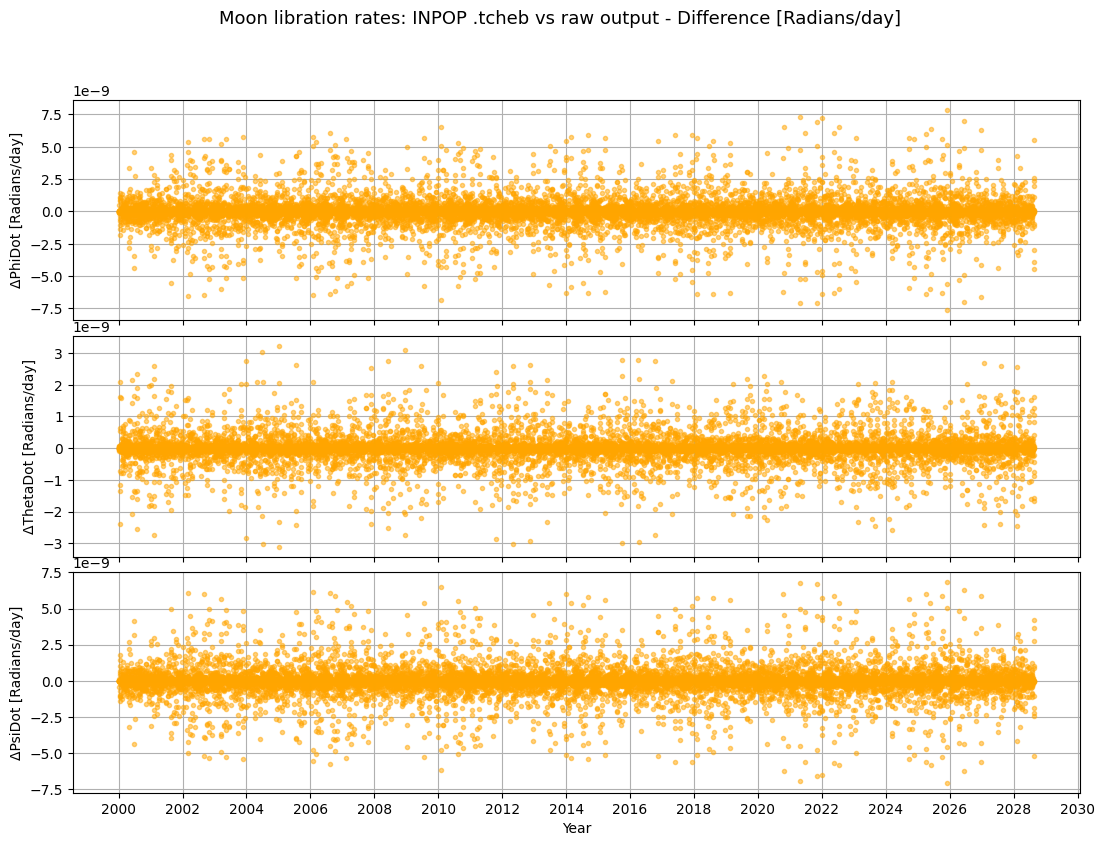

In [8]:
plot_compare_angle(jds, orient_calceph, orient_rawout, label="Moon libration angles: INPOP .tcheb vs raw output", show_overview=True, unwrap=True)
plot_compare_angledot(jds, orient_calceph, orient_rawout, label="Moon libration rates: INPOP .tcheb vs raw output")

## 3 · chebycode fit of the same samples

The raw samples are fitted with chebycode at the standard settings for these quantities — orbit: 4 d granules, order 12, C¹ Lobatto nodes using the velocities as derivatives; angles: 8 d granules, order 9 — and compared with the raw output exactly as in §2.


In [9]:
# Orbit: 4 d granules, order 12 (13 coefficients) is the standard; order 13 would go below
# the .tcheb residual (smaller tail estimate).
fit = ChebyshevSeries.from_samples(jd_int, jd_frac, p_moon[:lastidx], v_moon[:lastidx], 
                                   granule_len=4, order=12, dist=1, npoints=10)
p_moon_fit = fit.evaluate_jd(jd_int, jd_frac)
v_moon_fit = fit.evaluate_deriv(jd_int, jd_frac)
pv_moon_fit = np.concatenate([p_moon_fit, v_moon_fit], axis=1)

In [10]:
# Angles: 8 d granules, order 9 (10 coefficients) is the standard. psi wraps by ~2π in the
# raw output; orientation=True unwraps the angles before fitting. dist=2 leaves a noise-like
# residual; dist=4 tracks CALCEPH more closely but with visible structure.
fit_angles = ChebyshevSeries.from_samples(jd_int, jd_frac, orient_rawout[:,:3], orient_rawout[:,3:], 
                                          granule_len=8, order=9, dist=2, orientation=True)
o_moon_fit = fit_angles.evaluate_jd(jd_int, jd_frac)
od_moon_fit = fit_angles.evaluate_deriv(jd_int, jd_frac)
ood_moon_fit = np.concatenate([o_moon_fit, od_moon_fit], axis=1)

### At the sample epochs

`report()` checks the fit itself — continuity across granule edges and the decay of the coefficients. `validate()` compares the fit and its derivative with the samples it was built from. The figures then repeat §2 with the chebycode fit in place of the `.tcheb`.


In [11]:
fit.report()

ChebyshevSeries(order=12, n_granules=2616, ndim=3, jd=[2451545.0, 2462009.0])
──────────────────────────────────────────────────
  Continuity   C⁰ max jump  : 3.47e-18
               C¹ max jump  : 7.78e-16
  Truncation   last coeff   : 4.20e-15
               decay-rate   : 0.08
               converged    : True
──────────────────────────────────────────────────


Samples   max  error : 3.16858e-15
          RMS  error : 2.29512e-16
          mean error : -6.91643e-20


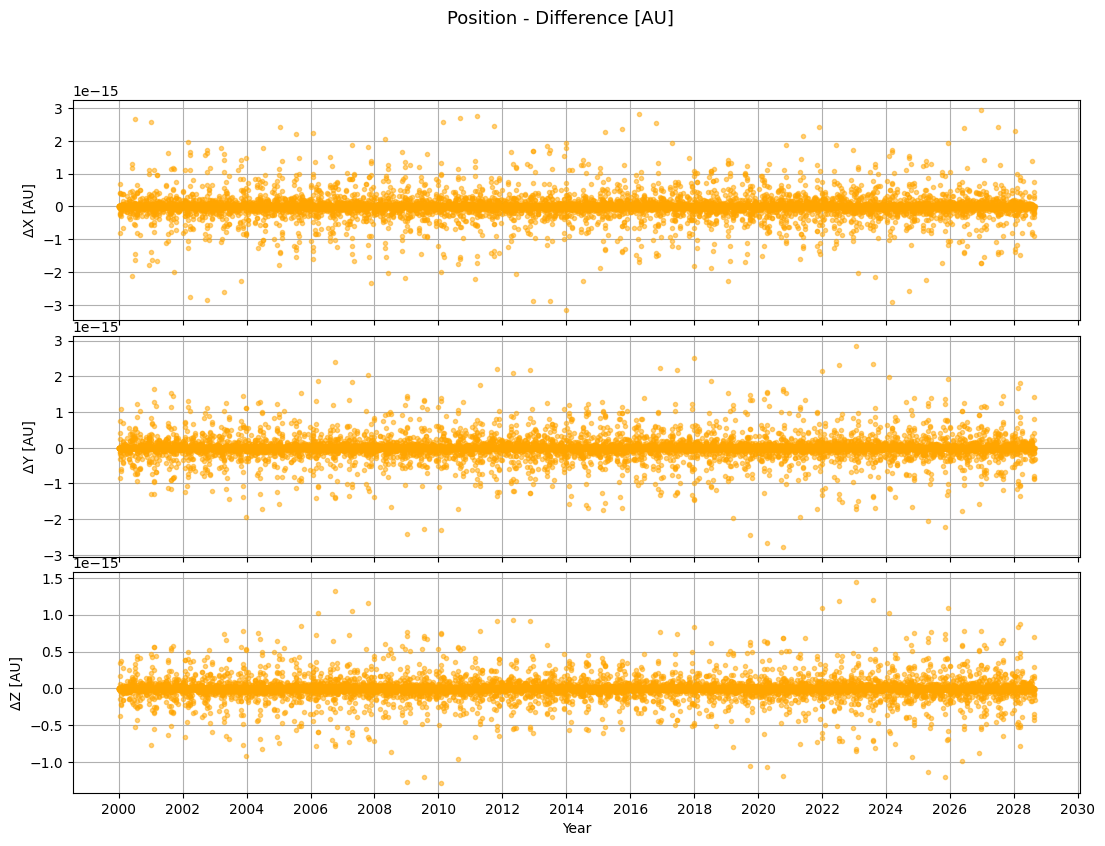

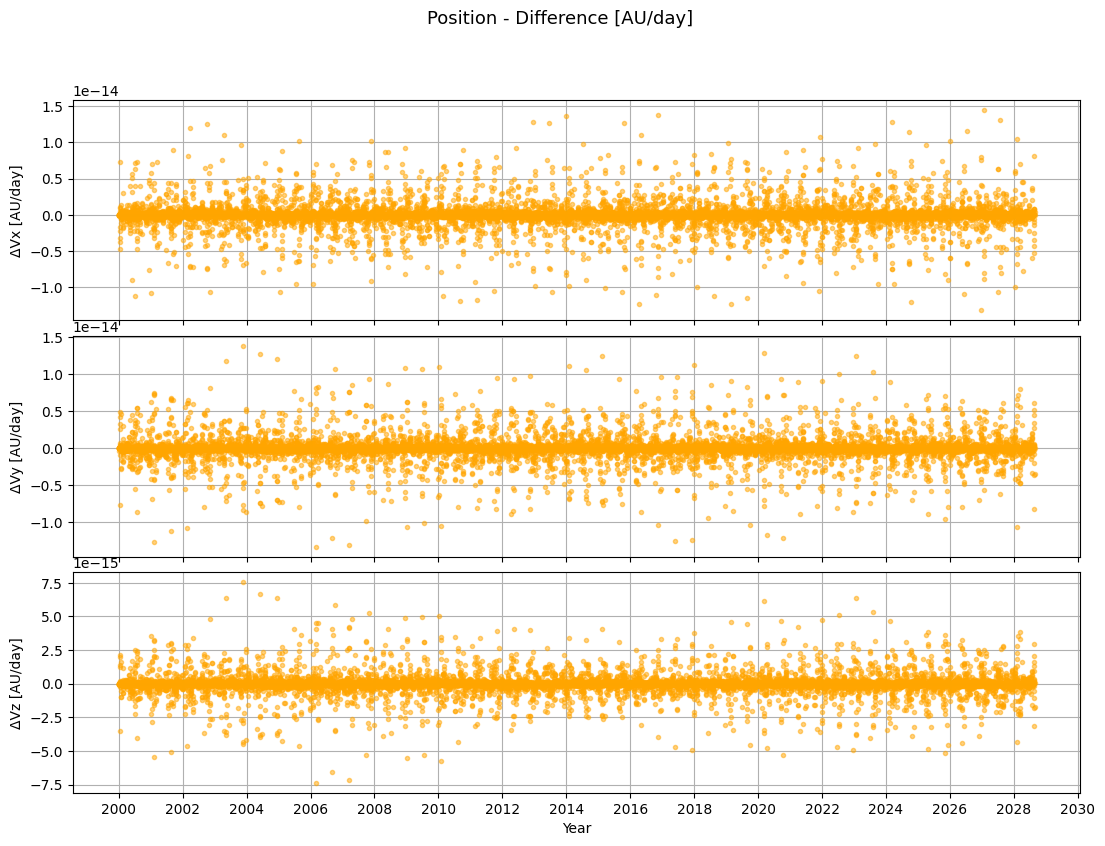

In [12]:
fit.validate(jd_int, jd_frac, np.concatenate([p_moon[:lastidx], v_moon[:lastidx]], axis=1))

In [13]:
dp = (p_moon_fit - pv_rawout[:, :3]).astype(np.float64) * AU * 1e6   # mm
print(f"Moon position, chebycode fit - raw output: max {np.max(np.abs(dp)):.2f} mm, RMS {np.sqrt(np.mean(dp**2)):.2f} mm")


Moon position, chebycode fit - raw output: max 0.47 mm, RMS 0.03 mm


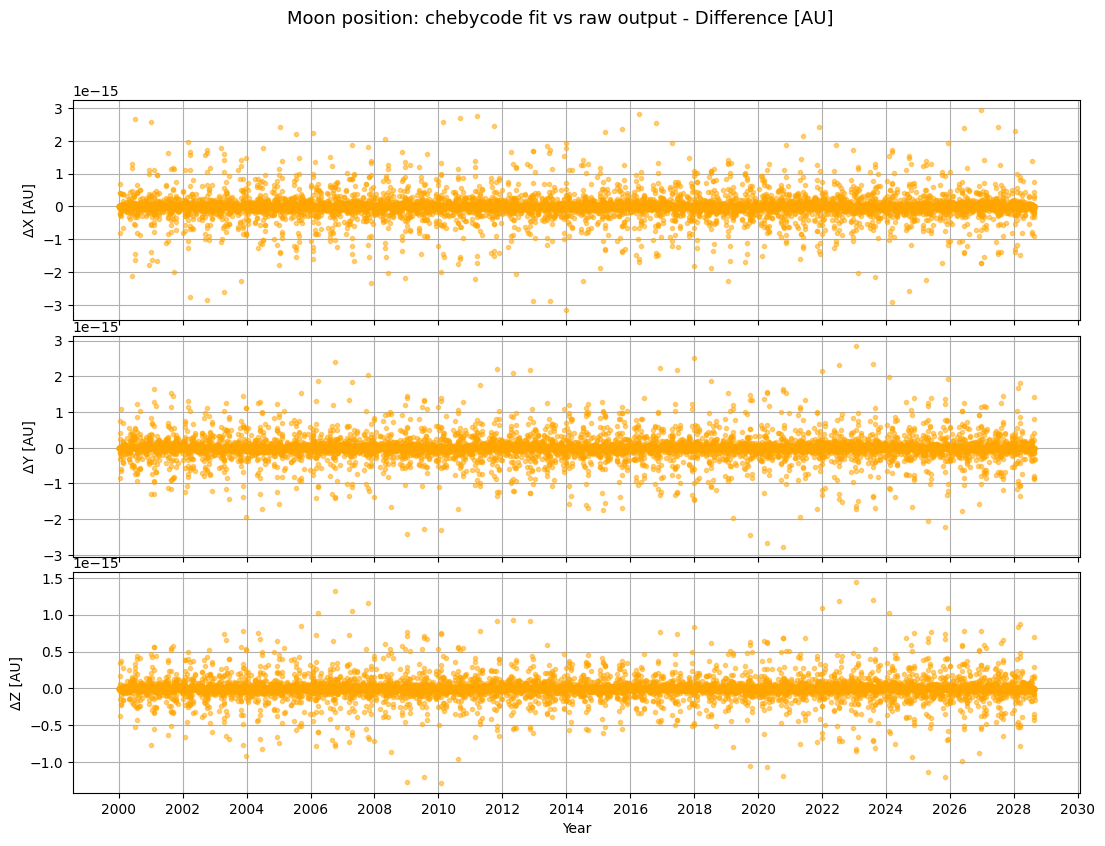

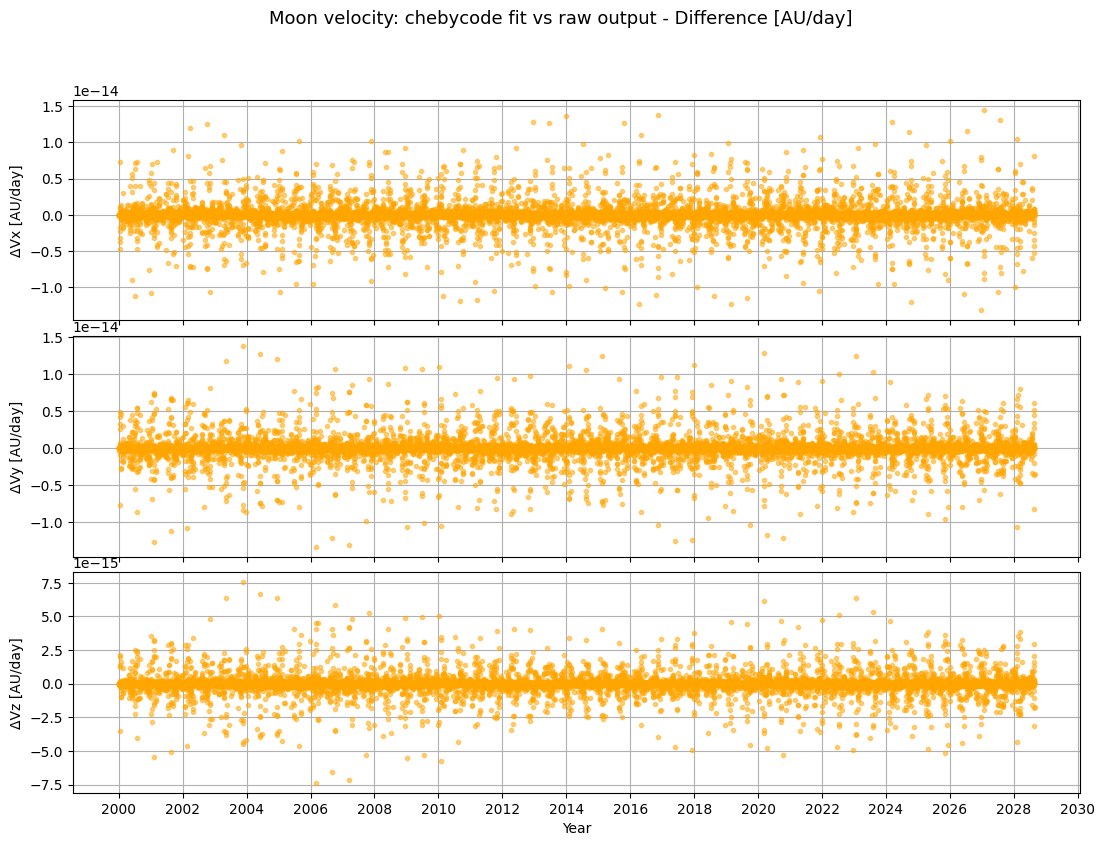

In [14]:
plot_compare_p(jds, pv_moon_fit, pv_rawout, label="Moon position: chebycode fit vs raw output", show_overview=0)
plot_compare_v(jds, pv_moon_fit, pv_rawout, label="Moon velocity: chebycode fit vs raw output")


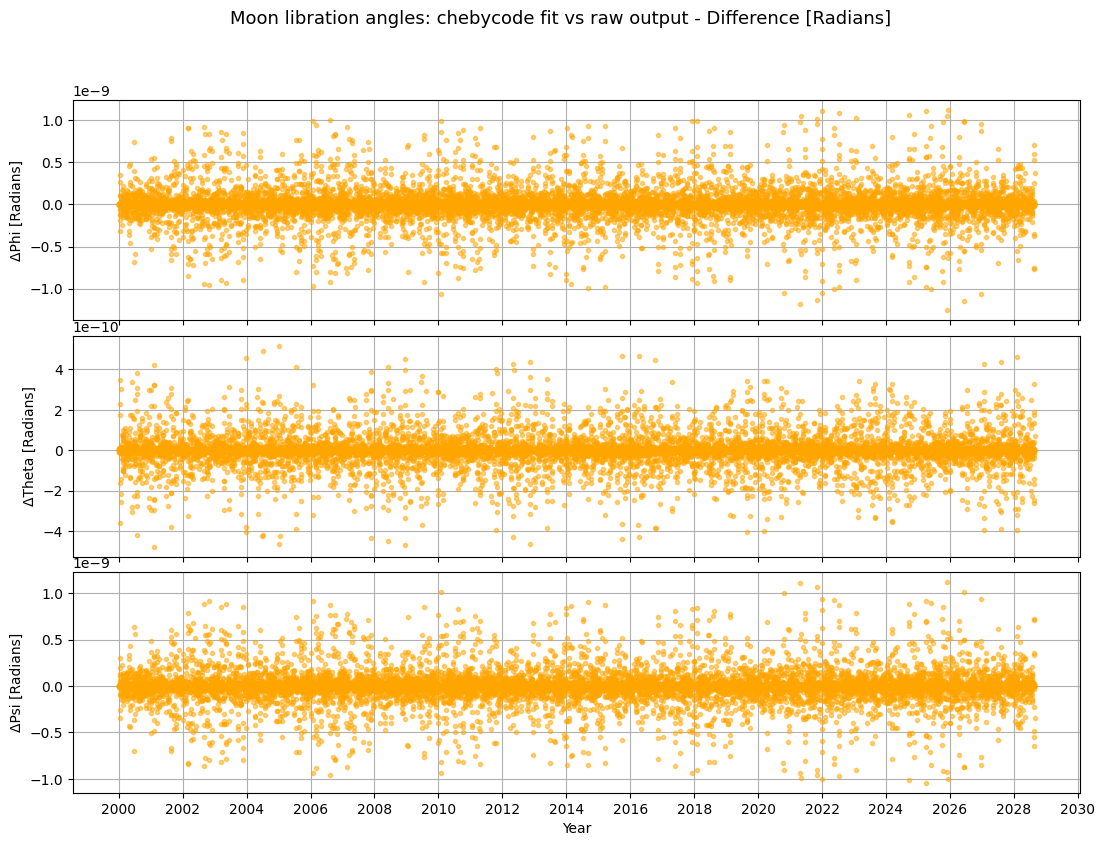

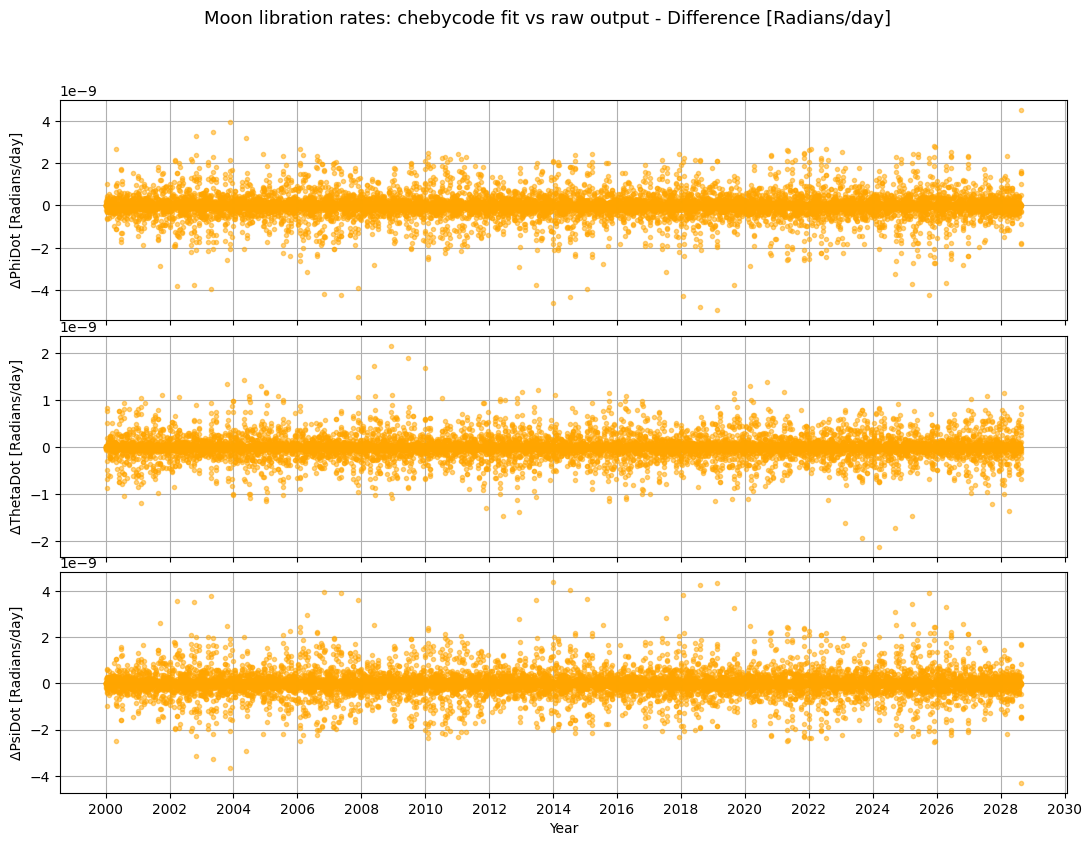

In [15]:
plot_compare_angle(jds, ood_moon_fit, orient_rawout, label="Moon libration angles: chebycode fit vs raw output", show_overview=0, unwrap=1)
plot_compare_angledot(jds, ood_moon_fit, orient_rawout, label="Moon libration rates: chebycode fit vs raw output", show_overview=0)


## 4 · Between the samples: chebycode vs the `.tcheb`

A fit can match its samples and still misbehave between them. On a grid offset from the samples (0.556 d steps from J2000 + 0.02 d, 28 yr), the chebycode fit is compared with CALCEPH's evaluation of the `.tcheb`. Both represent the same integration, so the difference is the two representation errors combined.


In [16]:
timegrid_new = TimeGrid.from_start_end(
    TimeScalar.from_float(JD_J2000 + 0.02),
    TimeScalar.from_float(JD_J2000 + 28 * 365.25),
    0.556,
)
jd0 = timegrid_new.jd_int
jdt = timegrid_new.jd_frac

In [17]:
# chebycode fit
p_moon_fit_new = fit.evaluate(jd0, jdt)
v_moon_fit_new = fit.evaluate_deriv(jd0, jdt)
pv_moon_fit_new = np.concatenate([p_moon_fit_new, v_moon_fit_new], axis=1)

o_moon_fit_new = fit_angles.evaluate_jd(jd0, jdt)
od_moon_fit_new = fit_angles.evaluate_deriv(jd0, jdt)
ood_moon_fit_new = np.concatenate([o_moon_fit_new, od_moon_fit_new], axis=1)

# INPOP .tcheb through CALCEPH
peph = CalcephBin.open(str(PATH_TCHEB))
pv_calceph_new = []
orient_calceph_new = []
for i, jd0_int in enumerate(jd0):
    PV = peph.compute_unit(jd0_int, jdt[i], 301, 399, Constants.UNIT_AU + Constants.UNIT_DAY + Constants.USE_NAIFID)
    O  = peph.orient_unit(jd0_int, jdt[i], NaifId.MOON, Constants.USE_NAIFID + Constants.UNIT_RAD + Constants.UNIT_DAY)
    pv_calceph_new.append(PV)
    orient_calceph_new.append(O)
peph.close()
pv_calceph_new = np.array(pv_calceph_new)
orient_calceph_new = np.array(orient_calceph_new)


Samples   max  error : 1.64799e-17
          RMS  error : 3.82523e-18
          mean error : -9.08957e-21


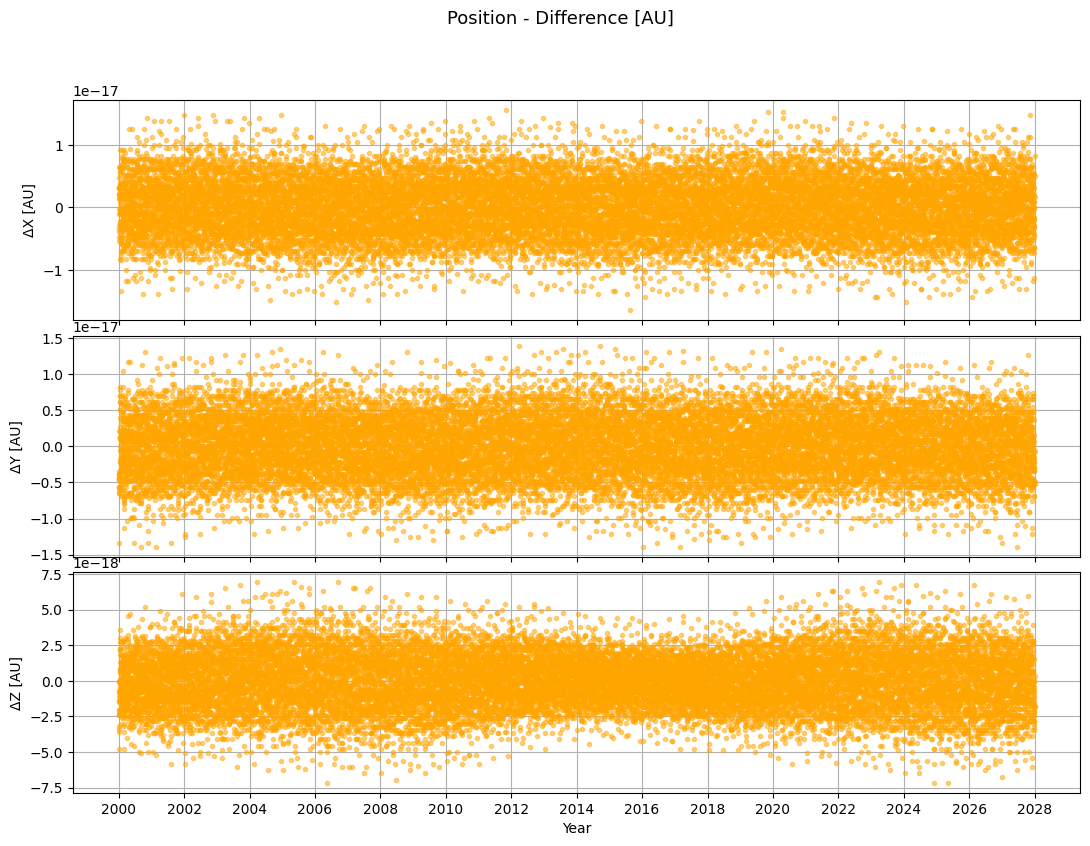

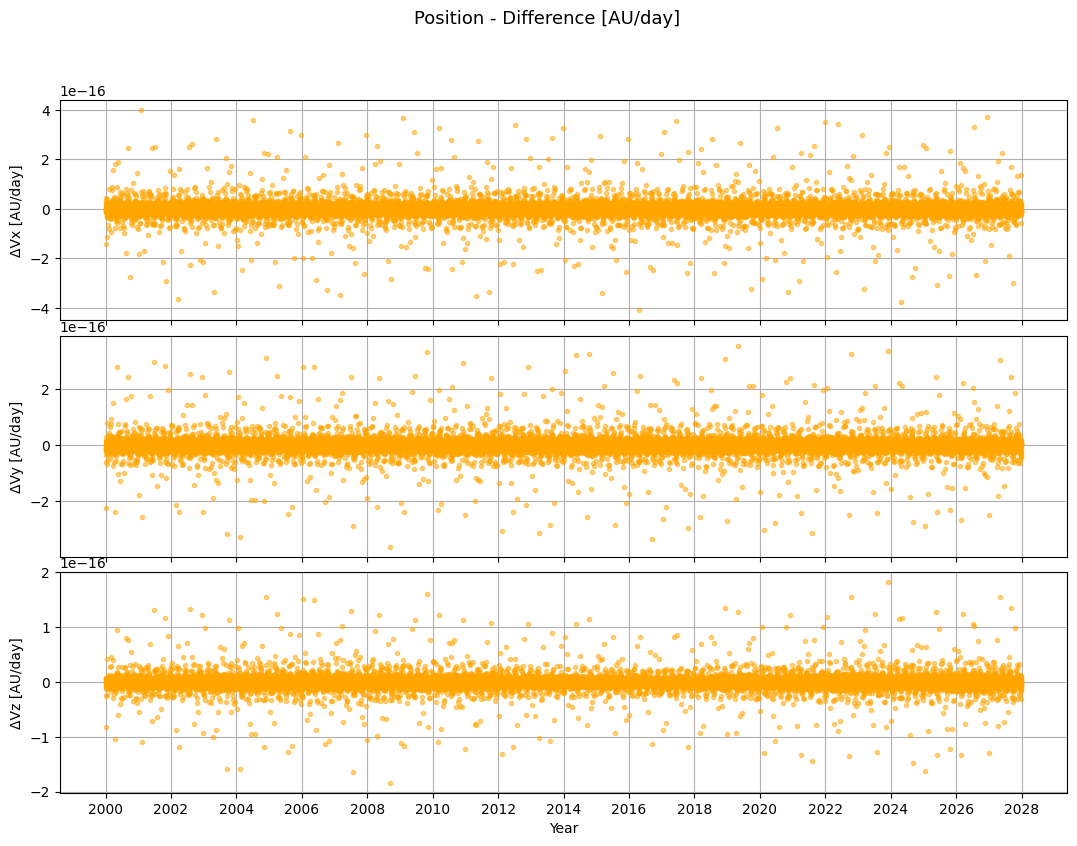

In [18]:
fit.validate(jd0,jdt, pv_calceph_new)

In [19]:
dp = (p_moon_fit_new - pv_calceph_new[:, :3]).astype(np.float64) * AU * 1e9   # µm
print(f"Moon position, chebycode fit - .tcheb between samples: max {np.max(np.abs(dp)):.2f} µm, RMS {np.sqrt(np.mean(dp**2)):.2f} µm")


Moon position, chebycode fit - .tcheb between samples: max 2.47 µm, RMS 0.57 µm


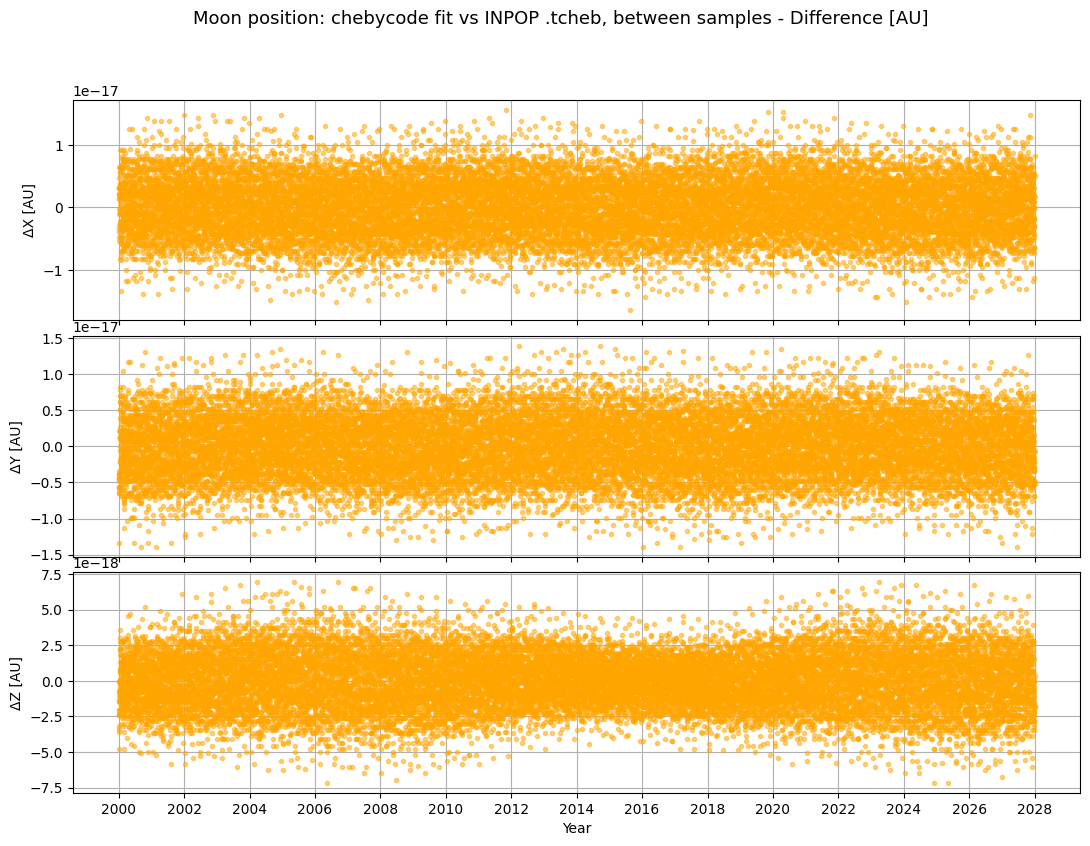

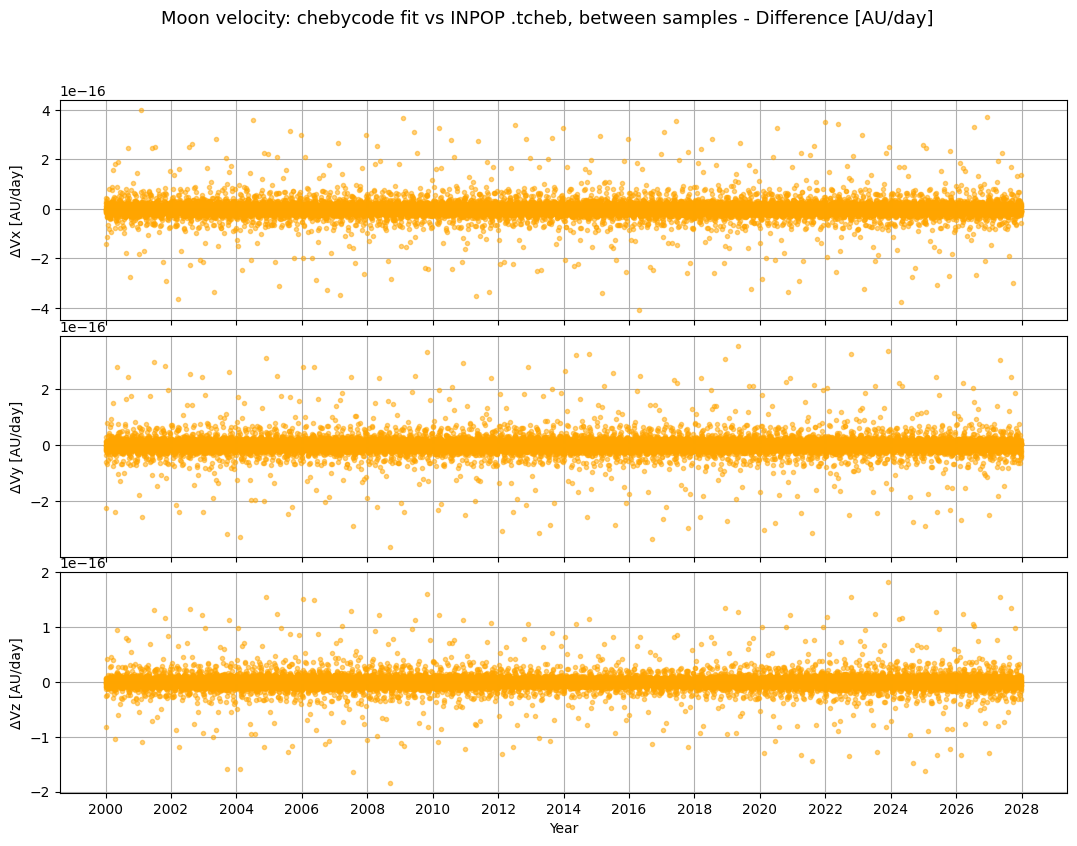

In [20]:
plot_compare_p(jd0+jdt, pv_moon_fit_new, pv_calceph_new, label="Moon position: chebycode fit vs INPOP .tcheb, between samples")
plot_compare_v(jd0+jdt, pv_moon_fit_new, pv_calceph_new, label="Moon velocity: chebycode fit vs INPOP .tcheb, between samples")


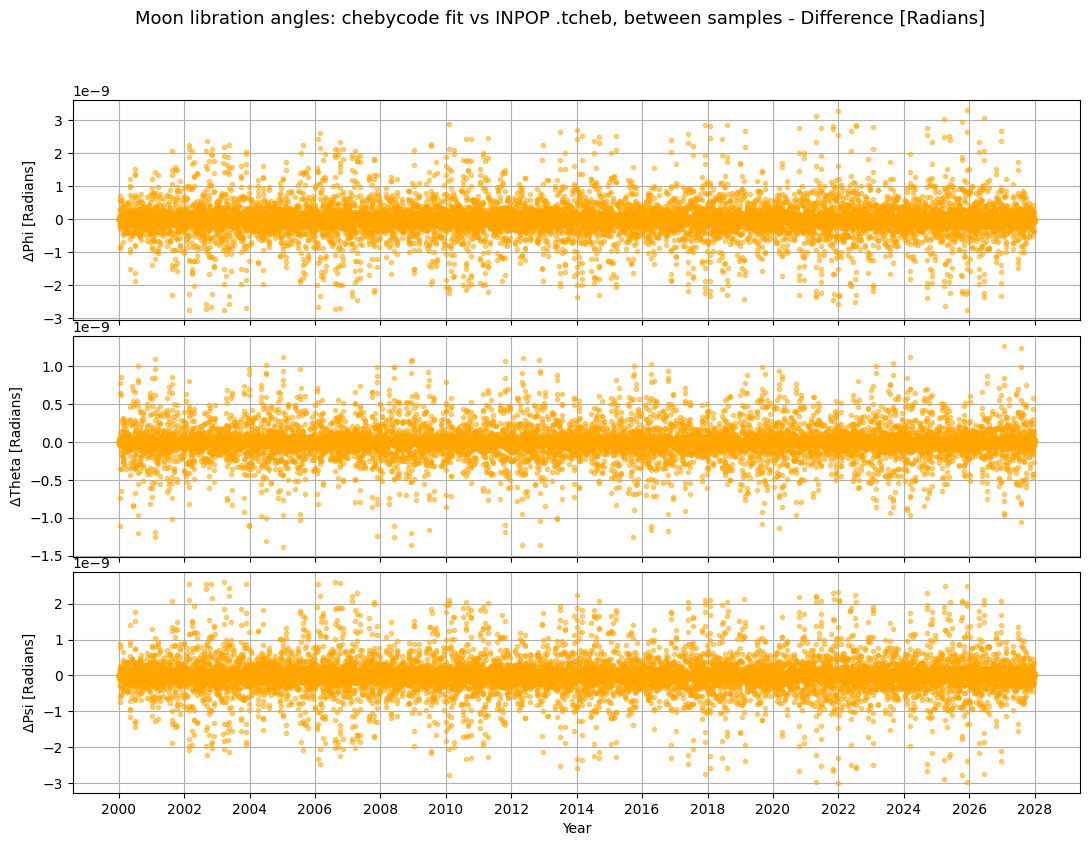

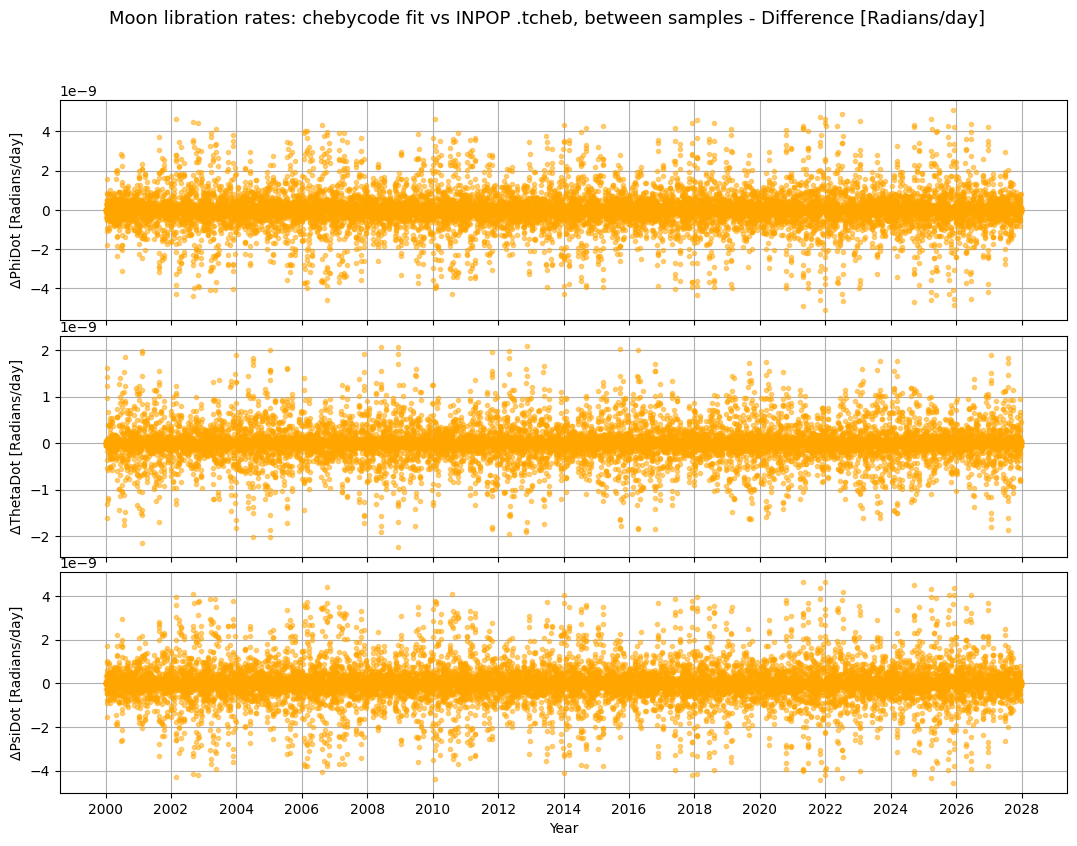

In [21]:
plot_compare_angle(jd0+jdt, ood_moon_fit_new, orient_calceph_new, label="Moon libration angles: chebycode fit vs INPOP .tcheb, between samples")
plot_compare_angledot(jd0+jdt, ood_moon_fit_new, orient_calceph_new, label="Moon libration rates: chebycode fit vs INPOP .tcheb, between samples")


## 5 · Writing and reading back the `.asc`

The orbit fit is written in the INPOP-style ASCII format and read back; the read-back series must reproduce the fit.


In [22]:
fit.to_asc("../output/nb06_moon_pos.asc", title="Moon Position [AU] w.r.t. Earth")


In [23]:
moon_fit = ChebyshevSeries.from_asc("../output/nb06_moon_pos.asc")
print(f"round trip, max |read back - fit|: {np.max(np.abs(moon_fit.evaluate(jd0, jdt) - p_moon_fit_new)):.1e} AU")


round trip, max |read back - fit|: 0.0e+00 AU


## 6 · Evaluator cross-check: chebycode vs CALCEPH on the INPOP TCG−TCB ASC

The INPOP `.asc` time-ephemeris file is an *export* of the Chebyshev data stored inside the `.dat` — not an independent fit. That makes the pair (CALCEPH internal query, chebycode ASC evaluation) a clean cross-check of the two **evaluators** on identical coefficients, and it is why `03_validation_tcg_inpop.ipynb` treats their difference as pure evaluation rounding. Test at **random epochs** (arbitrary phases inside every granule):

- If the `.asc` were an independent refit, truncation residuals would rise orders of magnitude above float64 rounding somewhere inside the granules (for scale: chebycode fits of TEMPUS series reach ~1e-13 s, notebooks 08–09, and of the Moon orbit ~1e-15 AU, §3).
- If the coefficients are identical, CALCEPH's recurrence and chebycode's Clenshaw can only differ by last-bit rounding: ≤ ~1 ulp of the value, everywhere.

Expected result: max = 1.00 ulp, RMS = 0.01 ulp — ≈ 99.99 % of epochs bit-identical, max |diff| ~4e-16 s. These are the numbers quoted in the paper's Chebyshev section.

100000 random epochs across 18720 granules
max |diff| = 4.441e-16 s
in ulp of |TCG-TCB|: max 1.00, RMS 0.01
fraction bit-identical: 0.9999


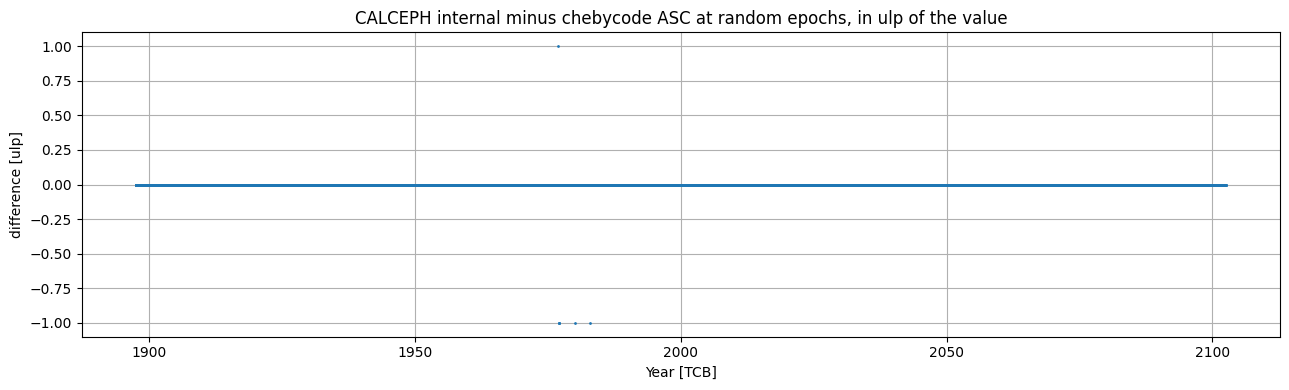

In [24]:
asc_ref = ChebyshevSeries.from_asc("../data/time_ephem/inpop19a_TCB_m100_p100_asc_pos_TCG.asc")
rng = np.random.default_rng(42)
jd_rand = np.sort(rng.uniform(asc_ref.jd_start + 0.5, asc_ref.jd_end - 0.5, 100000))
ji_r, jf_r = jd_split(jd_rand)

eph = CalcephEphem.open(["../data/ephem/inpop19a_TCB_m100_p100_tcg.dat"])
tcg_cal_r = np.asarray(eph.time_offset_jd("TCG-TCB", ji_r, jf_r))
eph.close()
tcg_asc_r = asc_ref.evaluate(ji_r, jf_r)

n_ulp = (tcg_cal_r - tcg_asc_r) / np.spacing(np.abs(tcg_cal_r))
print(f"{len(jd_rand)} random epochs across {asc_ref.n_granules} granules")
print(f"max |diff| = {np.max(np.abs(tcg_cal_r - tcg_asc_r)):.3e} s")
print(f"in ulp of |TCG-TCB|: max {np.max(np.abs(n_ulp)):.2f}, RMS {np.sqrt(np.mean(n_ulp**2)):.2f}")
print(f"fraction bit-identical: {np.mean(n_ulp == 0.0):.4f}")

plt.figure(figsize=(13, 4))
plt.plot((jd_rand - 2451545.0) / 365.25 + 2000.0, n_ulp, ".", ms=2)
plt.title("CALCEPH internal minus chebycode ASC at random epochs, in ulp of the value")
plt.xlabel("Year [TCB]")
plt.ylabel("difference [ulp]")
plt.grid(True)
plt.tight_layout()
plt.show()

## 7 · Summary

| comparison | result |
|---|---|
| INPOP `.tcheb` − raw output (§2) | Moon position 0.47 mm max, 0.03 mm RMS |
| chebycode fit − raw output (§3) | Moon position 0.47 mm max, 0.03 mm RMS |
| chebycode fit − INPOP `.tcheb`, between samples (§4) | Moon position 2.5 µm max, 0.6 µm RMS |
| `.asc` write and read back (§5) | exact |
| chebycode − CALCEPH on identical coefficients, INPOP19a TCG − TCB (§6) | ≤ 1 ulp (4.4×10⁻¹⁶ s), 99.99 % bit-identical |

With the same granule length and order, chebycode and INPOP's own fit agree to micrometres, so the 0.47 mm is set by that choice of order and granule length, not by the fitting code; reading coefficients back adds nothing above float64 rounding.
